| Step | Neighbors | Neighbor profiles | Probe |
|---|---|---|---|
| E0 | ✗ | ✗ | ✗ |
| E1 | ✓ | ✗ | ✗ |
| E2 | ✓ | ✓ | ✗ |
| E3 | ✓ | ✓ | ✓ |
| E4 | ✓ | ✓ | ✓ (multiple) |


[NEEDED]:
- `annotations.parquet`: from the annotation notebook (needed only for E2,E3,E4). Make sure to put it in the appropriate drive directory.

**Results** are saved to `sta221/runs` after each run, so a disconnect loses at most the run in progress.
After a disconnect, run Sections 1–9 again, then Section 11; finished runs are skipped.


In [2]:
!pip -q install "transformers>=4.51,<5" sentence-transformers faiss-cpu

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio-client 2.7.2 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
diffusers 0.42.1 requires huggingface-hub<3.0,>=1.32.0, but you have huggingface-hub 0.36.2 which is incompatible.
gradio 6.31.0 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.


In [3]:
from google.colab import drive
drive.mount("/content/drive")

import os
DRIVE_DIR = "/content/drive/MyDrive/sta221"
DATA_DIR = f"{DRIVE_DIR}/data"
RUNS_DIR = f"{DRIVE_DIR}/runs"
RESULTS_DIR = f"{DRIVE_DIR}/results"
for d in [DATA_DIR, RUNS_DIR, RESULTS_DIR]:
    os.makedirs(d, exist_ok=True)

STEPS = ["E0", "E1", "E2", "E3"]   # E2/E3 are skipped automatically until annotations exist
SEEDS = [0,1,2]
EPOCHS = 3
BATCH_SIZE = 8                     # A100 40/80 GB; use 4 on a ~20 GB GPU
ACCUM_STEPS = 2                    # keep BATCH_SIZE * ACCUM_STEPS = 16

NUM_NEIGHBORS = 5
NEIGHBOR_TOKENS = 96               # how much of each neighbor prompt to show
QUERY_TOKENS = 192                 # how much of the query prompt to show
PROBE_TOKENS = 32                  # how much of the probe model's answer to show
PROBE_MODEL = "mistralai/mixtral-8x7b-chat"
SPLIT_SEED = 123
print(os.listdir(DATA_DIR))

import ast, glob, json, random, time
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import faiss
import matplotlib.pyplot as plt
from torch.utils.data import DataLoader
from transformers import AutoTokenizer, AutoModel, get_linear_schedule_with_warmup
from sklearn.metrics import roc_auc_score, log_loss
from scipy.optimize import minimize_scalar

print(torch.cuda.get_device_name(0), "| bf16:", torch.cuda.is_bf16_supported())
assert torch.cuda.is_bf16_supported(), "This GPU lacks bfloat16; switch the runtime to an A100/L4"

Mounted at /content/drive
['prompts.parquet', 'arrays.npz', 'annotation_parts', 'annotations.parquet', 'probes.parquet']


Clean data for training


In [5]:
def to_plain_text(value):
    if isinstance(value, str) and value.startswith("["):
        try:
            value = ast.literal_eval(value)
        except Exception:
            pass
    if isinstance(value, (list, tuple)):
        return " ".join(str(v) for v in value)
    return str(value)


if not os.path.exists(f"{DATA_DIR}/arrays.npz"):
    from huggingface_hub import hf_hub_download
    from sentence_transformers import SentenceTransformer
    from sklearn.model_selection import train_test_split

    raw = pd.read_pickle(hf_hub_download("withmartian/routerbench", "routerbench_0shot.pkl", repo_type="dataset"))
    raw = raw[~raw["eval_name"].str.contains("mt-bench", case=False)].copy()
    raw["text"] = raw["prompt"].apply(to_plain_text)
    raw = raw.drop_duplicates("text").reset_index(drop=True)

    cost_columns = [c for c in raw.columns if c.endswith("|total_cost")]
    models = [c.split("|")[0] for c in cost_columns]
    Y = (raw[models].astype(float).values >= 0.5).astype(np.float32)
    C = np.nan_to_num(raw[cost_columns].astype(float).values)
    raw["probe"] = raw[f"{PROBE_MODEL}|model_response"].apply(to_plain_text)

    all_rows, benchmark = np.arange(len(raw)), raw["eval_name"].values
    train_idx, test_idx = train_test_split(all_rows, test_size=0.2, stratify=benchmark, random_state=SPLIT_SEED)
    train_idx, val_idx = train_test_split(train_idx, test_size=0.125, stratify=benchmark[train_idx], random_state=SPLIT_SEED)

    embedder = SentenceTransformer("sentence-transformers/all-MiniLM-L6-v2", device="cuda")
    E = embedder.encode(raw["text"].tolist(), batch_size=256, normalize_embeddings=True,
                        show_progress_bar=True).astype("float32")

    raw[["text", "eval_name", "probe"]].to_parquet(f"{DATA_DIR}/prompts.parquet")
    np.savez(f"{DATA_DIR}/arrays.npz", Y=Y, C=C, E=E, train_idx=train_idx, val_idx=val_idx,
             test_idx=test_idx, models=np.array(models), probe_model=PROBE_MODEL)
    del embedder; torch.cuda.empty_cache()
    print("prepared", len(raw), "prompts")

arrays.npz found; using existing data


In [6]:
def load_data(data_dir=DATA_DIR):
    arrays = np.load(f"{data_dir}/arrays.npz", allow_pickle=True)
    data = {
        "prompts": pd.read_parquet(f"{data_dir}/prompts.parquet"),
        "Y": arrays["Y"], "C": arrays["C"], "E": arrays["E"],
        "train_idx": arrays["train_idx"], "val_idx": arrays["val_idx"], "test_idx": arrays["test_idx"],
        "models": list(arrays["models"]), "probe_model": str(arrays["probe_model"]),
    }
    data["avg_cost"] = data["C"][data["train_idx"]].mean(axis=0)
    data["cheapest_first"] = np.argsort(data["avg_cost"])
    ann_file = f"{data_dir}/annotations.parquet"
    data["annotations"] = pd.read_parquet(ann_file) if os.path.exists(ann_file) else None
    return data


def short_name(model):
    """'mistralai/mixtral-8x7b-chat' -> 'mixtral-8x7b-chat'."""
    return model.split("/")[-1][:20]

Retreival search functionality

In [7]:
def build_neighbor_index(data):
    index = faiss.IndexFlatIP(data["E"].shape[1])
    index.add(data["E"][data["train_idx"]])
    data["index"] = index

def find_neighbors(data, rows, k=NUM_NEIGHBORS, duplicate_cutoff=0.98):
    """For each row, return the k most similar training prompts (excluding itself)."""
    similarities, positions = data["index"].search(data["E"][rows], k + 20)
    candidates = data["train_idx"][positions]
    all_neighbors, n_fallback = [], 0
    for i, row in enumerate(rows):
        keep = []
        for cand, sim in zip(candidates[i], similarities[i]):
            if cand != row and sim < duplicate_cutoff:
                keep.append(cand)
            if len(keep) == k:
                break
        if not keep:   # every candidate was a near-copy: use the nearest ones anyway
            keep = [c for c in candidates[i] if c != row][:k]
            n_fallback += 1
        while len(keep) < k:
            keep.append(keep[-1])
        all_neighbors.append(keep)
    if n_fallback:
        print(f"note: {n_fallback} of {len(rows)} rows had only near-duplicate neighbors")
    return np.array(all_neighbors)

In [8]:
def shorten(text, tokenizer, max_tokens):
    ids = tokenizer(text, add_special_tokens=False, truncation=True, max_length=max_tokens)["input_ids"]
    return tokenizer.decode(ids)


def results_line(data, n):
    bits = "".join(str(int(v)) for v in data["Y"][n])
    cheapest = "none"
    for j in data["cheapest_first"]:
        if data["Y"][n, j] == 1:
            rel = data["avg_cost"][j] / data["avg_cost"].max()
            cheapest = f"{short_name(data['models'][j])} (cost {rel:.2f})"
            break
    return f"Results: {bits} | cheapest correct: {cheapest}"


def profile_line(data, n):
    a = data["annotations"].iloc[n]
    steps = a["reasoning_steps"]
    return f"Profile: {a['difficulty']} | {steps} step{'s' if steps != 1 else ''} | {a['format']}"

Below Function Builds the router data

In [9]:
def build_router_inputs(data, rows, tokenizer, use_neighbors, use_profiles, use_probe, use_multi_probe=False):
    texts = data["prompts"]["text"].tolist()
    if use_multi_probe:
        probe_texts = {m: data["probes"][m].fillna("").tolist() for m in data["probe_models"]}
    elif use_probe:
        probe_texts = {data["probe_model"]: data["prompts"]["probe"].fillna("").tolist()}
    else:
        probe_texts = {}
    neighbor_ids = find_neighbors(data, rows) if use_neighbors else None
    inputs = []
    for i, row in enumerate(rows):
        parts = []
        if use_neighbors:
            for j, n in enumerate(neighbor_ids[i]):
                block = f"Neighbor {j + 1}: {shorten(texts[n], tokenizer, NEIGHBOR_TOKENS)}"
                if use_profiles:
                    block += "\n" + profile_line(data, n)
                block += "\n" + results_line(data, n)
                parts.append(block)
        query = f"Query: {shorten(texts[row], tokenizer, QUERY_TOKENS)}"
        for m, answers in probe_texts.items():
            query += (f"\nProbe ({short_name(m)}, first {PROBE_TOKENS} tokens): "
                      f"{shorten(answers[row], tokenizer, PROBE_TOKENS)}")
        parts.append(query + "\nPrediction:")
        inputs.append("\n\n".join(parts))
    return inputs

Decoder Model

In [10]:
def make_head(hidden_size, num_models):
    return nn.Sequential(nn.Dropout(0.1), nn.Linear(hidden_size, 512), nn.GELU(),
                         nn.Dropout(0.1), nn.Linear(512, num_models))


class DecoderRouter(nn.Module):
    model_name = "Qwen/Qwen2.5-0.5B"

    def __init__(self, num_models, use_neighbors=False, use_profiles=False, use_probe=False, use_multi_probe=False):
        super().__init__()
        if use_profiles and not use_neighbors:
            raise ValueError("use_profiles needs use_neighbors")
        self.use_neighbors, self.use_profiles = use_neighbors, use_profiles
        self.use_probe, self.use_multi_probe = use_probe, use_multi_probe
        self.tokenizer = AutoTokenizer.from_pretrained(self.model_name)
        self.tokenizer.padding_side = "left"
        self.backbone = AutoModel.from_pretrained(self.model_name)
        self.head = make_head(self.backbone.config.hidden_size, num_models)

    def make_inputs(self, data, rows):
        return build_router_inputs(data, rows, self.tokenizer, self.use_neighbors,
                                   self.use_profiles, self.use_probe, self.use_multi_probe)

    def forward(self, input_ids, attention_mask):
        hidden = self.backbone(input_ids=input_ids, attention_mask=attention_mask).last_hidden_state
        return self.head(hidden[:, -1])


Batching, prediction, training with early stopping, and latency.

In [11]:
def set_seed(seed):
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)


def make_loader(router, data, texts, rows, batch_size, shuffle):
    examples = list(zip(texts, data["Y"][rows]))
    def collate(batch):
        enc = router.tokenizer([t for t, _ in batch], padding=True, return_tensors="pt")
        labels = torch.tensor(np.array([y for _, y in batch]))
        return enc["input_ids"], enc["attention_mask"], labels
    return DataLoader(examples, batch_size=batch_size, shuffle=shuffle, collate_fn=collate)


@torch.no_grad()
def predict_logits(router, data, texts, rows, batch_size=32):
    router.eval(); outputs = []
    for ids, mask, _ in make_loader(router, data, texts, rows, batch_size, False):
        with torch.autocast("cuda", dtype=torch.bfloat16):
            outputs.append(router(ids.cuda(), mask.cuda()).float().cpu().numpy())
    return np.concatenate(outputs)

In [12]:
def train_router(router, data, train_texts, val_texts, epochs, batch_size, accum_steps):
    train_rows, val_rows = data["train_idx"], data["val_idx"]
    loader = make_loader(router, data, train_texts, train_rows, batch_size, True)
    optimizer = torch.optim.AdamW([
        {"params": router.backbone.parameters(), "lr": 2e-5},
        {"params": router.head.parameters(), "lr": 1e-3},
    ], weight_decay=0.01)
    total_steps = epochs * len(loader) // accum_steps
    scheduler = get_linear_schedule_with_warmup(optimizer, int(0.06 * total_steps), total_steps)
    loss_fn = nn.BCEWithLogitsLoss()

    best_val, best_weights = float("inf"), None
    for epoch in range(epochs):
        router.train()
        for step, (ids, mask, labels) in enumerate(loader):
            with torch.autocast("cuda", dtype=torch.bfloat16):
                logits = router(ids.cuda(), mask.cuda())
            loss = loss_fn(logits.float(), labels.cuda()) / accum_steps
            loss.backward()
            if (step + 1) % accum_steps == 0:
                torch.nn.utils.clip_grad_norm_(router.parameters(), 1.0)
                optimizer.step(); scheduler.step(); optimizer.zero_grad()
            if step % 500 == 0:
                print(f"  epoch {epoch} step {step}/{len(loader)} loss {loss.item() * accum_steps:.4f}", flush=True)

        val_probs = 1 / (1 + np.exp(-predict_logits(router, data, val_texts, val_rows)))
        val_loss = log_loss(data["Y"][val_rows].ravel(), np.clip(val_probs, 1e-6, 1 - 1e-6).ravel())
        print(f"  == epoch {epoch}: validation loss {val_loss:.4f}", flush=True)
        if val_loss < best_val:
            best_val = val_loss
            best_weights = {k: w.detach().cpu().clone() for k, w in router.state_dict().items()}

    router.load_state_dict(best_weights)
    return best_val


@torch.no_grad()
def measure_latency_ms(router, text, repeats=20):
    router.eval()
    enc = router.tokenizer([text], return_tensors="pt").to("cuda")
    with torch.autocast("cuda", dtype=torch.bfloat16):
        for _ in range(3):
            router(enc["input_ids"], enc["attention_mask"])
        torch.cuda.synchronize(); start = time.perf_counter()
        for _ in range(repeats):
            router(enc["input_ids"], enc["attention_mask"])
        torch.cuda.synchronize()
    return (time.perf_counter() - start) / repeats * 1000

Train and Test Iteration Function Below. It saves validation/test predictions and run info to Drive. Finished runs (and runs missing annotations) are skipped.

In [13]:
LADDER = {
    "E0": dict(use_neighbors=False, use_profiles=False, use_probe=False),
    "E1": dict(use_neighbors=True,  use_profiles=False, use_probe=False),
    "E2": dict(use_neighbors=True,  use_profiles=True,  use_probe=False),
    "E3": dict(use_neighbors=True,  use_profiles=True,  use_probe=True),
    "E4": dict(use_neighbors=True, use_profiles=True, use_probe=False, use_multi_probe=True)
}


def train_one(data, use_neighbors, use_profiles, use_probe, seed, use_multi_probe=False,
              epochs=EPOCHS, batch_size=BATCH_SIZE, accum_steps=ACCUM_STEPS, out_dir=RUNS_DIR):
    condition = "neighbors" if use_neighbors else "query"
    if use_profiles: condition += "+profiles"
    if use_probe: condition += "+probe"
    if use_multi_probe: condition += "+multiprobe"
    run_name = f"decoder_{condition}_seed{seed}"

    if os.path.exists(f"{out_dir}/{run_name}.npz"):
        print(f"skip {run_name} (already done)"); return
    if use_profiles and data["annotations"] is None:
        print(f"skip {run_name} (needs annotations.parquet)"); return

    print(f"\n===== {run_name} =====", flush=True)
    set_seed(seed)
    router = DecoderRouter(len(data["models"]), use_neighbors, use_profiles, use_probe, use_multi_probe).cuda()

    train_texts = router.make_inputs(data, data["train_idx"])
    val_texts = router.make_inputs(data, data["val_idx"])
    test_texts = router.make_inputs(data, data["test_idx"])
    lengths = [len(router.tokenizer(t).input_ids) for t in train_texts[:500]]

    start = time.time()
    best_val = train_router(router, data, train_texts, val_texts, epochs, batch_size, accum_steps)
    minutes = (time.time() - start) / 60

    val_logits = predict_logits(router, data, val_texts, data["val_idx"])
    test_logits = predict_logits(router, data, test_texts, data["test_idx"])
    latency = measure_latency_ms(router, test_texts[0])

    np.savez(f"{out_dir}/{run_name}.npz", val_logits=val_logits, test_logits=test_logits)
    if seed == 0:
      weights = {k: v.to(torch.bfloat16) for k, v in router.state_dict().items()}
      torch.save(weights, f"{out_dir}/{run_name}_weights.pt")

    info = dict(run=run_name, arch="decoder", condition=condition, seed=seed, best_val_loss=best_val,
                train_minutes=minutes, latency_ms=latency, median_tokens=float(np.median(lengths)),
                gpu=torch.cuda.get_device_name(0))
    json.dump(info, open(f"{out_dir}/{run_name}.json", "w"), indent=1)
    print(info, flush=True)
    del router; torch.cuda.empty_cache()

Load data and build the neighbor index

In [14]:
data = load_data()
build_neighbor_index(data)
print("prompts:", len(data["prompts"]), "| train/val/test:",
      len(data["train_idx"]), len(data["val_idx"]), len(data["test_idx"]))

prompts: 36481 | train/val/test: 25536 3648 7297
annotations: found


In [15]:
PROBE_MODELS = ["mistralai/mixtral-8x7b-chat", "WizardLM/WizardLM-13B-V1.2", "mistralai/mistral-7b-chat"]

from huggingface_hub import hf_hub_download
raw = pd.read_pickle(hf_hub_download("withmartian/routerbench", "routerbench_0shot.pkl", repo_type="dataset"))
raw = raw[~raw["eval_name"].str.contains("mt-bench", case=False)].copy()
raw["text"] = raw["prompt"].apply(to_plain_text)
raw = raw.drop_duplicates("text").reset_index(drop=True)
assert len(raw) == len(data["prompts"]) and (raw["text"].values == data["prompts"]["text"].values).all(), \
    "rows don't match prompts.parquet"

probes = pd.DataFrame({m: raw[f"{m}|model_response"].fillna("").apply(to_plain_text) for m in PROBE_MODELS})
probes.to_parquet(f"{DATA_DIR}/probes.parquet")

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


routerbench_0shot.pkl:   0%|          | 0.00/99.6M [00:00<?, ?B/s]

In [16]:
data["probes"] = pd.read_parquet(f"{DATA_DIR}/probes.parquet")
data["probe_models"] = PROBE_MODELS
cols = [data["models"].index(m) for m in PROBE_MODELS]
print("probe cost per query: $", data["C"][data["test_idx"]][:, cols].sum(axis=1).mean().round(6))

probe cost per query: $ 0.000253


Run the ablations for every seed in `SEEDS`. Safe to rerun after a disconnect.

In [41]:
for step in STEPS:
    for seed in SEEDS:
        train_one(data, seed=seed, **LADDER[step])
print("\nAll requested runs finished.")

skip decoder_query_seed0 (already done)
skip decoder_query_seed1 (already done)
skip decoder_query_seed2 (already done)
skip decoder_neighbors_seed0 (already done)
skip decoder_neighbors_seed1 (already done)
skip decoder_neighbors_seed2 (already done)
skip decoder_neighbors+profiles_seed0 (already done)
skip decoder_neighbors+profiles_seed1 (already done)
skip decoder_neighbors+profiles_seed2 (already done)
skip decoder_neighbors+profiles+probe_seed0 (already done)
skip decoder_neighbors+profiles+probe_seed1 (already done)

===== decoder_neighbors+profiles+probe_seed2 =====
note: 268 of 25536 rows had only near-duplicate neighbors
note: 38 of 3648 rows had only near-duplicate neighbors
note: 77 of 7297 rows had only near-duplicate neighbors
tokens per input (median / 95th pct): [901 980]
  epoch 0 step 0/3192 loss 0.9429
  epoch 0 step 500/3192 loss 0.5113
  epoch 0 step 1000/3192 loss 0.7393
  epoch 0 step 1500/3192 loss 0.4979
  epoch 0 step 2000/3192 loss 0.5039
  epoch 0 step 2500/


Evalution

In [42]:
Y, C = data["Y"], data["C"]
val_rows, test_rows = data["val_idx"], data["test_idx"]
models = data["models"]
sigmoid = lambda x: 1 / (1 + np.exp(-x))

single_models = {m: (C[test_rows, j].mean(), Y[test_rows, j].mean()) for j, m in enumerate(models)}
best_j = int(np.argmax([acc for _, acc in single_models.values()]))
best_cost = C[test_rows, best_j].mean()

oracle_choice = []
for r in test_rows:
    correct = [j for j in data["cheapest_first"] if Y[r, j] == 1]
    oracle_choice.append(correct[0] if correct else data["cheapest_first"][0])
oracle_choice = np.array(oracle_choice)
oracle_point = (C[test_rows, oracle_choice].mean(), Y[test_rows, oracle_choice].mean())

num_correct = Y[test_rows].sum(axis=1)
hard = (num_correct >= 1) & ((num_correct == 1) | (Y[test_rows, best_j] == 0))
probe_j = models.index(data["probe_model"])

**The cost rule.** Pick the model with the highest (probability correct − λ × cost). λ is chosen on validation: the largest value that keeps 98% of the best model's accuracy.

In [43]:
cost_weight = data["avg_cost"] / data["avg_cost"].max()
lambdas = np.concatenate([[0], np.logspace(-3, 1, 400)])

def probes_for(condition):
    if "multiprobe" in condition:
        return [models.index(m) for m in data["probe_models"]]
    if "probe" in condition:
        return [probe_j]
    return []

def choose_models(P, lam, with_probe=False):
    weight = cost_weight.copy()
    weight[np.array(with_probe or [], dtype=int)] = 0.0
    return np.argmax(P - lam * weight, axis=1)

def total_cost(rows, choices, with_probe=False):
    probed = np.array(with_probe or [], dtype=int)
    probe_cost = C[rows][:, probed].sum(axis=1)
    chosen_cost = np.where(np.isin(choices, probed), 0.0, C[rows, choices])
    return probe_cost + chosen_cost

def pick_lambda(P_val, with_probe=False, target=0.98):
    goal = target * Y[val_rows, best_j].mean()
    for lam in sorted(lambdas, reverse=True):
        if Y[val_rows, choose_models(P_val, lam, with_probe)].mean() >= goal:
            return lam
    return 0.0

**Score one router** and **calibrate** its probabilities on validation.

In [44]:
def score_router(name, P_val, P_test, with_probe=False):
    lam = pick_lambda(P_val, with_probe)
    choices = choose_models(P_test, lam, with_probe)
    hits = Y[test_rows, choices]
    cost = total_cost(test_rows, choices, with_probe)
    shares = np.bincount(choices, minlength=len(models)) / len(choices)
    aucs = [roc_auc_score(Y[test_rows, j], P_test[:, j]) for j in range(len(models)) if 0 < Y[test_rows, j].mean() < 1]
    row = dict(router=name, chosen_lambda=round(lam, 4), mean_auc=np.mean(aucs), accuracy=hits.mean(),
               cost_vs_best_model=cost.mean() / best_cost, hard_accuracy=hits[hard].mean(),
               most_picked=f"{short_name(models[shares.argmax()])} {shares.max():.0%}")
    picks = [choose_models(P_test, l, with_probe) for l in lambdas]
    curve = [(total_cost(test_rows, p, with_probe).mean(), Y[test_rows, p].mean()) for p in picks]
    return row, hits, np.array(curve)

def calibrate(val_logits, test_logits):
    temps = []
    for j in range(val_logits.shape[1]):
        loss_at = lambda t: log_loss(Y[val_rows, j], np.clip(sigmoid(val_logits[:, j] / t), 1e-6, 1 - 1e-6), labels=[0, 1])
        temps.append(minimize_scalar(loss_at, bounds=(0.25, 5), method="bounded").x)
    temps = np.array(temps)
    return sigmoid(val_logits / temps), sigmoid(test_logits / temps)




In [45]:
def accuracy_at(P_test, budget, with_probe):
    best_all, best_hard = np.nan, np.nan
    for lam in lambdas:
        picks = choose_models(P_test, lam, with_probe)
        if total_cost(test_rows, picks, with_probe).mean() <= budget:
            hits = Y[test_rows, picks]
            if np.isnan(best_all) or hits.mean() > best_all:
                best_all, best_hard = hits.mean(), hits[hard].mean()
    return best_all, best_hard

budgets = [2e-4, 3e-4, 5e-4, 1e-3, 2e-3]
rows = []
for info_file in sorted(glob.glob(f"{RUNS_DIR}/*.json")):
    info = json.load(open(info_file))
    saved = np.load(info_file.replace(".json", ".npz"))
    _, P_test = calibrate(saved["val_logits"], saved["test_logits"])
    for b in budgets:
        acc_all, acc_hard = accuracy_at(P_test, b, probes_for(info["condition"]))
        rows.append({"condition": info["condition"], "seed": info["seed"],
                     "budget": f"${b:g}", "all": acc_all, "hard": acc_hard})
table = pd.DataFrame(rows)

print(table.pivot_table(index="condition", columns="budget", values="all", aggfunc="mean").round(3))
print(table.pivot_table(index="condition", columns="budget", values="hard", aggfunc="mean").round(3))

budget                         $0.0002  $0.0003  $0.0005  $0.001  $0.002
condition                                                               
neighbors                        0.701    0.737    0.762   0.775   0.805
neighbors+profiles               0.714    0.740    0.761   0.783   0.809
neighbors+profiles+multiprobe      NaN    0.673    0.731   0.772   0.812
neighbors+profiles+probe         0.688    0.723    0.744   0.773   0.807
query                            0.677    0.738    0.759   0.769   0.769
budget                         $0.0002  $0.0003  $0.0005  $0.001  $0.002
condition                                                               
neighbors                        0.370    0.367    0.347   0.324   0.307
neighbors+profiles               0.371    0.374    0.344   0.335   0.315
neighbors+profiles+multiprobe      NaN    0.361    0.368   0.335   0.290
neighbors+profiles+probe         0.367    0.370    0.363   0.322   0.300
query                            0.371    0.361    

**Baselines and trained runs.**

In [46]:
results, hits_by_group, curves = [], {}, {}

def add_result(name, group, P_val, P_test, with_probe=False):
    row, hits, curve = score_router(name, P_val, P_test, probes_for(info["condition"]))
    row["group"] = group
    results.append(row); curves[name] = curve
    hits_by_group.setdefault(group, []).append(hits)

add_result("kNN", "kNN", Y[find_neighbors(data, val_rows, k=100)].mean(axis=1),
           Y[find_neighbors(data, test_rows, k=100)].mean(axis=1))

benchmark, train_rows = data["prompts"]["eval_name"].values, data["train_idx"]
per_bench = {b: Y[train_rows][benchmark[train_rows] == b].mean(axis=0) for b in np.unique(benchmark[train_rows])}
add_result("DimensionBest", "DimensionBest",
           np.vstack([per_bench[b] for b in benchmark[val_rows]]),
           np.vstack([per_bench[b] for b in benchmark[test_rows]]))

for info_file in sorted(glob.glob(f"{RUNS_DIR}/*.json")):
    info = json.load(open(info_file))
    saved = np.load(info_file.replace(".json", ".npz"))
    P_val, P_test = calibrate(saved["val_logits"], saved["test_logits"])
    add_result(info["run"], f"{info['arch']}:{info['condition']}", P_val, P_test,
               with_probe=("probe" in info["condition"]))
print(len(results), "routers scored")

note: 31 of 3648 rows had only near-duplicate neighbors
note: 64 of 7297 rows had only near-duplicate neighbors
16 routers scored


**Summary table** (mean and standard deviation across seeds).

In [47]:
table = pd.DataFrame(results)
table.to_csv(f"{RESULTS_DIR}/all_runs.csv", index=False)
metrics = ["mean_auc", "accuracy", "cost_vs_best_model", "hard_accuracy"]
summary = table.groupby("group")[metrics].agg(["mean", "std"]).round(3)
summary.to_csv(f"{RESULTS_DIR}/summary.csv")
display(summary)
display(table[["router", "chosen_lambda", "most_picked"]])

infos = pd.DataFrame([json.load(open(f)) for f in glob.glob(f"{RUNS_DIR}/*.json")])
if len(infos):
    display(infos.groupby("condition")[["latency_ms", "median_tokens", "train_minutes"]].mean().round(1))

mean_auc        accuracy         \
                                          mean    std     mean    std   
group                                                                   
DimensionBest                            0.716    NaN    0.833    NaN   
decoder:neighbors                        0.734  0.002    0.830  0.002   
decoder:neighbors+profiles               0.735  0.002    0.830  0.003   
decoder:neighbors+profiles+multiprobe    0.778  0.004    0.829  0.002   
decoder:neighbors+profiles+probe         0.759  0.004    0.829  0.004   
decoder:query                            0.733  0.001    0.829  0.000   
kNN                                      0.714    NaN    0.828    NaN   

                                      cost_vs_best_model        hard_accuracy  \
                                                    mean    std          mean   
group                                                                           
DimensionBest                                      0.869    NaN         0.196   
decoder:neighbors                                  0.749  0.070         0.276   
decoder:neighbors+profiles                         0.754  0.057         0.286   
decoder:neighbors+profiles+multiprobe              0.786  0.082         0.263   
decoder:neighbors+profiles+probe                   0.777  0.072         0.270   
decoder:query                                      0.775  0.056         0.286   
kNN                                                0.774    NaN         0.264   

                                              
                                         std  
group                                         
DimensionBest                            NaN  
decoder:neighbors                      0.010  
decoder:neighbors+profiles             0.011  
decoder:neighbors+profiles+multiprobe  0.006  
decoder:neighbors+profiles+probe       0.017  
decoder:query                          0.001  
kNN                                      NaN

,router,chosen_lambda,most_picked
0,kNN,0.0749,gpt-4-1106-preview 71%
1,DimensionBest,0.0989,gpt-4-1106-preview 84%
2,decoder_neighbors+profiles+multiprobe_seed0,0.0989,gpt-4-1106-preview 60%
3,decoder_neighbors+profiles+multiprobe_seed1,0.1059,gpt-4-1106-preview 62%
4,decoder_neighbors+profiles+multiprobe_seed2,0.0518,gpt-4-1106-preview 68%
5,decoder_neighbors+profiles+probe_seed0,0.0841,gpt-4-1106-preview 60%
6,decoder_neighbors+profiles+probe_seed1,0.0966,gpt-4-1106-preview 60%
7,decoder_neighbors+profiles+probe_seed2,0.0542,gpt-4-1106-preview 76%
8,decoder_neighbors+profiles_seed0,0.0922,gpt-4-1106-preview 62%
9,decoder_neighbors+profiles_seed1,0.1217,gpt-4-1106-preview 62%


,latency_ms,median_tokens,train_minutes
condition,,,
neighbors,32.2,825.0,36.0
neighbors+profiles,31.5,880.0,38.5
neighbors+profiles+multiprobe,32.1,942.5,44.5
neighbors+profiles+probe,32.4,901.5,41.1
query,32.6,164.0,23.4


**Paired comparisons** up the ladder and against kNN. A 95% CI that excludes 0 means the difference is real.

In [48]:
rng = np.random.default_rng(0)

def paired_difference(a, b, mask=None, n_boot=2000):
    if mask is not None:
        a, b = a[mask], b[mask]
    boot = [(a[i] - b[i]).mean() for i in (rng.integers(0, len(a), len(a)) for _ in range(n_boot))]
    return (a - b).mean(), np.percentile(boot, [2.5, 97.5])

avg_hits = {g: np.mean(h, axis=0) for g, h in hits_by_group.items()}
ladder = ["query", "neighbors", "neighbors+profiles", "neighbors+profiles+probe"]
pairs = [(f"decoder:{u}", f"decoder:{l}") for l, u in zip(ladder, ladder[1:])]
pairs += [(f"decoder:{s}", "kNN") for s in ladder]

lines = []
for a, b in pairs:
    if a in avg_hits and b in avg_hits:
        for label, mask in [("all", None), ("hard", hard)]:
            diff, ci = paired_difference(avg_hits[a], avg_hits[b], mask)
            lines.append(f"{a} vs {b} [{label}]: {diff:+.3f}  95% CI [{ci[0]:+.3f}, {ci[1]:+.3f}]")
print("\n".join(lines))
open(f"{RESULTS_DIR}/paired_tests.txt", "w").write("\n".join(lines))

decoder:neighbors vs decoder:query [all]: +0.001  95% CI [-0.002, +0.003]
decoder:neighbors vs decoder:query [hard]: -0.010  95% CI [-0.021, +0.000]
decoder:neighbors+profiles vs decoder:neighbors [all]: +0.001  95% CI [-0.001, +0.003]
decoder:neighbors+profiles vs decoder:neighbors [hard]: +0.010  95% CI [+0.001, +0.019]
decoder:neighbors+profiles+probe vs decoder:neighbors+profiles [all]: -0.002  95% CI [-0.005, +0.001]
decoder:neighbors+profiles+probe vs decoder:neighbors+profiles [hard]: -0.016  95% CI [-0.027, -0.006]
decoder:query vs kNN [all]: +0.001  95% CI [-0.004, +0.005]
decoder:query vs kNN [hard]: +0.022  95% CI [+0.003, +0.042]
decoder:neighbors vs kNN [all]: +0.001  95% CI [-0.003, +0.006]
decoder:neighbors vs kNN [hard]: +0.012  95% CI [-0.007, +0.031]
decoder:neighbors+profiles vs kNN [all]: +0.002  95% CI [-0.002, +0.007]
decoder:neighbors+profiles vs kNN [hard]: +0.022  95% CI [+0.003, +0.043]
decoder:neighbors+profiles+probe vs kNN [all]: +0.000  95% CI [-0.004, +0.

1084

**Accuracy vs cost** (seed 0 of each condition, plus baselines).

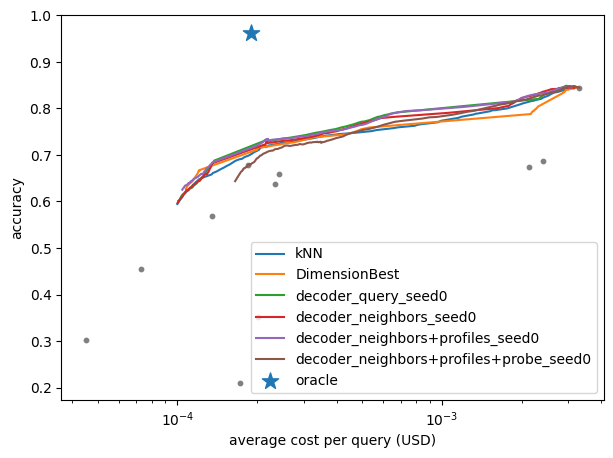

In [49]:
plt.figure(figsize=(7, 5))
for name in ["kNN", "DimensionBest"] + [f"decoder_{c}_seed0" for c in ladder]:
    if name in curves:
        plt.plot(curves[name][:, 0], curves[name][:, 1], label=name)
plt.scatter(*oracle_point, marker="*", s=150, label="oracle")
for cost, acc in single_models.values():
    plt.scatter(cost, acc, s=10, c="gray")
plt.xscale("log"); plt.xlabel("average cost per query (USD)"); plt.ylabel("accuracy"); plt.legend()
plt.savefig(f"{RESULTS_DIR}/cost_curves.png", dpi=150, bbox_inches="tight")
plt.show()